# Fase 5 — Especialização com LoRA
1. Gerar ~300 exemplos com o professor (`06_gerar_exemplos.py`), ~25% recusas, sem vazamento do teste.
2. **Revisar à mão** no terminal: `python scripts/07_revisar_exemplos.py` (não roda bem dentro do notebook) e exportar.
3. Treinar na GPU: rank 16, alpha 32, 2–3 épocas.
4. Juntar ao modelo, quantizar q4_K_M e importar no Ollama.

In [1]:
import sys, os
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ / "scripts"))
print(RAIZ)

.


In [2]:
# %run scripts/06_gerar_exemplos.py --alvo 300   # descomente: leva ~20–40 min com o professor local

In [3]:
%run scripts/07_revisar_exemplos.py --exportar
print(open('treino/estatisticas.md', encoding='utf-8').read())


=== treino/treino.jsonl ===


Exemplos aprovados: 324 de 435 gerados; rejeitados: 111; editados: 97
Por tipo: {'resposta': 233, 'recusa_fora_escopo': 26, 'recusa_sem_base': 65}
Recusas: 28% (meta ~25%)

Próximo: python scripts/08_treinar_lora.py
Exemplos aprovados: 324 de 435 gerados; rejeitados: 111; editados: 97
Por tipo: {'resposta': 233, 'recusa_fora_escopo': 26, 'recusa_sem_base': 65}
Recusas: 28% (meta ~25%)



In [4]:
%run scripts/08_treinar_lora.py

W1108 15:03:06.451000 10192 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels



=== 292 exemplos de treino, 32 de validação — Qwen/Qwen2.5-1.5B-Instruct ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/292 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/292 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/292 [00:00<?, ? examples/s]

... (18 outputs left out)

{
  "modelo_hf": "Qwen/Qwen2.5-1.5B-Instruct",
  "rank": 16,
  "alpha": 32,
  "epocas": 3,
  "lr": 0.0002,
  "batch_efetivo": 16,
  "qlora_4bit": false,
  "n_treino": 292,
  "n_validacao": 32,
  "perda_treino_final": 0.15464303493499756,
  "perda_validacao_por_epoca": [
    0.21849969029426575,
    0.18601424992084503,
    0.1826254427433014
  ],
  "duracao_min": 13.0,
  "gpu": "NVIDIA GeForce RTX 4080"
}

=== Juntando adapter + modelo base (pesos completos em fp16) ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

.\modelos\mesclado
Próximo: python scripts/09_exportar_ollama.py


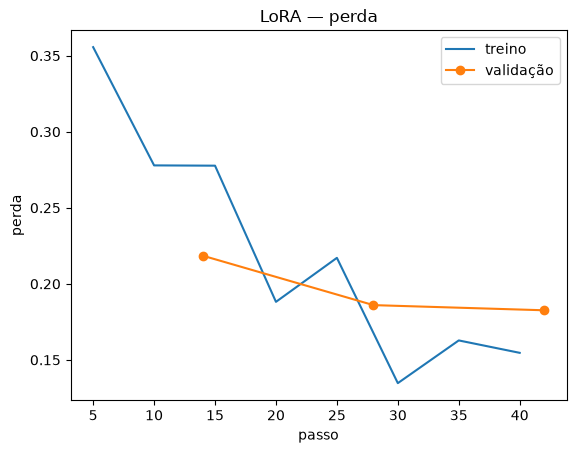

{'modelo_hf': 'Qwen/Qwen2.5-1.5B-Instruct', 'rank': 16, 'alpha': 32, 'epocas': 3, 'lr': 0.0002, 'batch_efetivo': 16, 'qlora_4bit': False, 'n_treino': 292, 'n_validacao': 32, 'perda_treino_final': 0.15464303493499756, 'perda_validacao_por_epoca': [0.21849969029426575, 0.18601424992084503, 0.1826254427433014], 'duracao_min': 13.0, 'gpu': 'NVIDIA GeForce RTX 4080'}


In [5]:
import json, matplotlib.pyplot as plt
h = json.load(open('modelos/lora-adapter/log_history.json'))
plt.plot([x['step'] for x in h if 'loss' in x], [x['loss'] for x in h if 'loss' in x], label='treino')
plt.plot([x['step'] for x in h if 'eval_loss' in x], [x['eval_loss'] for x in h if 'eval_loss' in x], 'o-', label='validação')
plt.xlabel('passo'); plt.ylabel('perda'); plt.legend(); plt.title('LoRA — perda'); plt.show()
print(json.load(open('treino/treino_lora.json')))

In [6]:
%run scripts/09_exportar_ollama.py


=== Template do modelo base (qwen2.5:1.5b-instruct) ===


$ ollama show qwen2.5:1.5b-instruct --modelfile


.\modelos\Modelfile escrito (0 PARAMETER copiados)

=== ollama create (quantizando para q4_K_M, alguns minutos) ===


$ ollama create passo-seguro-lora --quantize q4_K_M -f .\modelos\Modelfile
 
Error: unsupported --quantize "q4_K_M": supported types are int4, int8, nvfp4, mxfp4, mxfp8



SystemExit: falhou: ollama create passo-seguro-lora --quantize q4_K_M -f .\modelos\Modelfile